# Análise de Desempenho de Estudantes

**Dataset:** *Students Performance in Exams* (Kaggle) — 1.000 estudantes do ensino médio
dos EUA, com 5 atributos socioeconômicos/demográficos e 3 notas (matemática, leitura e escrita).

**Objetivo:** investigar quais fatores estão associados ao desempenho escolar e transformar
isso em recomendações acionáveis.

**Roteiro:**

| Etapa | O que é feito |
|---|---|
| 1. 🧹 Limpeza dos dados | Padronização de nomes, checagem de nulos/duplicatas, validação de domínio, outliers, tipagem e criação de variáveis derivadas |
| 2. 📊 Análise exploratória | Estatísticas descritivas, análise univariada, bivariada, correlações e testes de hipótese |
| 3. 📈 Visualizações | 9 gráficos que sustentam cada conclusão |
| 4. 🔍 Insights | 6 achados quantificados |
| 5. 📋 Conclusões e recomendações | Síntese + ações práticas + limitações |

## 0. Configuração do ambiente

Importamos as bibliotecas e fixamos um padrão visual único para todos os gráficos.
Definir o estilo **uma vez** no início evita repetir configuração em cada figura e garante
que todos os gráficos do relatório tenham a mesma identidade visual.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import warnings
warnings.filterwarnings("ignore")

# ---- Padrão visual único para todo o relatório ----
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["font.size"] = 10

# ---- Paleta de cores do projeto ----
COR_MAT, COR_LEI, COR_ESC = "#2E86AB", "#A23B72", "#F18F01"
PALETA = [COR_MAT, COR_LEI, COR_ESC]

# ---- Rótulos em português usados nos gráficos ----
NOMES_DISCIPLINA = {"nota_matematica": "Matemática",
                    "nota_leitura":    "Leitura",
                    "nota_escrita":    "Escrita"}

ROTULOS = {
    "female": "Feminino",              "male": "Masculino",
    "standard": "Padrão (paga)",       "free/reduced": "Gratuito/subsidiado",
    "completed": "Completou o curso",  "none": "Não fez o curso",
    "high school":        "Ensino médio completo",
    "some high school":   "Ensino médio incompleto",
    "some college":       "Superior incompleto",
    "associate's degree": "Curso técnico (associate)",
    "bachelor's degree":  "Graduação",
    "master's degree":    "Mestrado",
}

# ---- Exibição de tabelas no pandas ----
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Bibliotecas carregadas com sucesso.")
print(f"pandas     : {pd.__version__}")
print(f"numpy      : {np.__version__}")
print(f"seaborn    : {sns.__version__}")

Bibliotecas carregadas com sucesso.
pandas     : 3.0.2
numpy      : 2.4.4
seaborn    : 0.13.2


---

# 1. 🧹 Limpeza dos dados

A limpeza é o alicerce da análise: qualquer conclusão tirada de dados sujos é uma conclusão
errada com aparência de certeza. Aqui seguimos um **checklist de 8 verificações**:

1. Carregar e inspecionar visualmente
2. Conferir estrutura e tipos de dados
3. Padronizar nomes das colunas
4. Procurar valores ausentes
5. Procurar registros duplicados
6. Validar consistência das categorias
7. Validar domínio das notas e investigar outliers
8. Otimizar tipos e criar variáveis derivadas

### 1.1 Carregamento e primeira inspeção

`pd.read_csv()` lê o arquivo para um DataFrame. `.shape` devolve `(linhas, colunas)` e
`.head()` mostra as primeiras linhas — é o "olhar de relance" que revela problemas óbvios
(colunas deslocadas, separador errado, cabeçalho duplicado).

In [2]:
CAMINHO = "dados/StudentsPerformance.csv"
df = pd.read_csv(CAMINHO)

print(f"Dimensões do dataset: {df.shape[0]} linhas x {df.shape[1]} colunas")
df.head()

Dimensões do dataset: 1000 linhas x 8 colunas


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


### 1.2 Estrutura e tipos de dados

`.info()` resume, coluna a coluna: quantos valores **não-nulos** existem e qual o **tipo**.
É a forma mais rápida de detectar duas falhas clássicas: coluna numérica lida como texto
(por causa de vírgula decimal ou símbolo de moeda) e colunas com dados faltando.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


### 1.3 Padronização dos nomes das colunas

Os nomes originais têm **espaços** e **barras** (`race/ethnicity`, `math score`), o que
obriga a escrever `df["math score"]` em vez de `df.math_score` e quebra em várias bibliotecas.

Convertemos tudo para `snake_case` e, de quebra, traduzimos para português — o relatório
inteiro fica mais legível.

In [4]:
print("ANTES:")
print(list(df.columns))

renomear = {
    "gender":                      "genero",
    "race/ethnicity":              "grupo_etnico",
    "parental level of education": "escolaridade_pais",
    "lunch":                       "tipo_almoco",
    "test preparation course":     "curso_preparatorio",
    "math score":                  "nota_matematica",
    "reading score":               "nota_leitura",
    "writing score":               "nota_escrita",
}
df = df.rename(columns=renomear)

# Listas reutilizadas ao longo de toda a análise
NOTAS = ["nota_matematica", "nota_leitura", "nota_escrita"]
CATEGORICAS = ["genero", "grupo_etnico", "escolaridade_pais",
               "tipo_almoco", "curso_preparatorio"]

print("\nDEPOIS:")
print(list(df.columns))

ANTES:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

DEPOIS:
['genero', 'grupo_etnico', 'escolaridade_pais', 'tipo_almoco', 'curso_preparatorio', 'nota_matematica', 'nota_leitura', 'nota_escrita']


### 1.4 Verificação de valores ausentes

Somamos os nulos por coluna com `.isnull().sum()`. Se houvesse ausentes, as opções seriam
remover as linhas (`dropna`), imputar pela mediana (numéricas) ou pela moda (categóricas).

In [5]:
ausentes = pd.DataFrame({
    "valores_ausentes": df.isnull().sum(),
    "percentual_%": (df.isnull().sum() / len(df) * 100).round(2)
})
print(ausentes)
print(f"\nTotal de valores ausentes no dataset: {df.isnull().sum().sum()}")

                    valores_ausentes  percentual_%
genero                             0          0.00
grupo_etnico                       0          0.00
escolaridade_pais                  0          0.00
tipo_almoco                        0          0.00
curso_preparatorio                 0          0.00
nota_matematica                    0          0.00
nota_leitura                       0          0.00
nota_escrita                       0          0.00

Total de valores ausentes no dataset: 0


> ✅ **Resultado:** nenhum valor ausente. Nenhuma imputação é necessária.

### 1.5 Verificação de registros duplicados

Linhas idênticas normalmente indicam erro de coleta ou junção mal feita, e inflam
artificialmente qualquer média. `.duplicated().sum()` conta quantas existem.

In [6]:
n_dup = df.duplicated().sum()
print(f"Registros duplicados (linha inteira idêntica): {n_dup}")

if n_dup > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Duplicatas removidas. Novo total: {len(df)} linhas")
else:
    print("Nenhuma remoção necessária.")

Registros duplicados (linha inteira idêntica): 0
Nenhuma remoção necessária.


### 1.6 Consistência das variáveis categóricas

Um erro silencioso e muito comum: `"male"`, `"Male"` e `" male "` são tratados como **três
categorias diferentes** pelo pandas, o que quebra qualquer agrupamento.

Verificamos as categorias únicas de cada coluna e aplicamos `.str.strip().str.lower()`
como medida preventiva de padronização.

In [7]:
for col in CATEGORICAS:
    print(f"{col}  ({df[col].nunique()} categorias)")
    print(f"   -> {sorted(df[col].unique())}\n")

# Padronização preventiva: remove espaços nas bordas e uniformiza caixa
for col in CATEGORICAS:
    df[col] = df[col].str.strip().str.lower()

print("Padronização de texto (strip + lower) aplicada às 5 colunas categóricas.")

genero  (2 categorias)
   -> ['female', 'male']

grupo_etnico  (5 categorias)
   -> ['group A', 'group B', 'group C', 'group D', 'group E']

escolaridade_pais  (6 categorias)
   -> ["associate's degree", "bachelor's degree", 'high school', "master's degree", 'some college', 'some high school']

tipo_almoco  (2 categorias)
   -> ['free/reduced', 'standard']

curso_preparatorio  (2 categorias)
   -> ['completed', 'none']

Padronização de texto (strip + lower) aplicada às 5 colunas categóricas.


### 1.7 Validação de domínio e análise de outliers

Notas escolares devem estar entre **0 e 100**. Qualquer valor fora disso é erro de digitação
ou de sistema.

Em seguida procuramos *outliers* pelo **método IQR (intervalo interquartil)**:
tudo que estiver abaixo de `Q1 − 1,5×IQR` ou acima de `Q3 + 1,5×IQR` é sinalizado.

⚠️ **Decisão metodológica importante:** identificar um outlier **não** significa apagá-lo.
Aqui os valores extremos são notas baixas legítimas de alunos reais — remover essas linhas
mascararia justamente o problema que queremos estudar. Portanto: **sinalizamos e mantemos**.

In [8]:
print("--- Validação de domínio (0 a 100) ---")
for col in NOTAS:
    fora = df[(df[col] < 0) | (df[col] > 100)]
    print(f"{col:18s} min={df[col].min():3d}  max={df[col].max():3d}  "
          f"valores fora do intervalo: {len(fora)}")

print("\n--- Outliers pelo método IQR ---")
resumo_outliers = []
for col in NOTAS:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = df[(df[col] < lim_inf) | (df[col] > lim_sup)]
    resumo_outliers.append({
        "variavel": col, "Q1": q1, "Q3": q3, "IQR": iqr,
        "lim_inferior": round(lim_inf, 1), "lim_superior": round(lim_sup, 1),
        "n_outliers": len(out), "perc_%": round(len(out) / len(df) * 100, 2)
    })

print(pd.DataFrame(resumo_outliers).to_string(index=False))

--- Validação de domínio (0 a 100) ---
nota_matematica    min=  0  max=100  valores fora do intervalo: 0
nota_leitura       min= 17  max=100  valores fora do intervalo: 0
nota_escrita       min= 10  max=100  valores fora do intervalo: 0

--- Outliers pelo método IQR ---
       variavel    Q1    Q3   IQR  lim_inferior  lim_superior  n_outliers  perc_%
nota_matematica 57.00 77.00 20.00         27.00        107.00           8    0.80
   nota_leitura 59.00 79.00 20.00         29.00        109.00           6    0.60
   nota_escrita 57.75 79.00 21.25         25.90        110.90           5    0.50


Vamos olhar quem são esses casos extremos antes de decidir o que fazer com eles:

In [9]:
print("Os 5 alunos com pior desempenho médio:")
piores = df.assign(media=df[NOTAS].mean(axis=1)).nsmallest(5, "media")
print(piores[["genero", "tipo_almoco", "curso_preparatorio"] + NOTAS + ["media"]]
      .to_string(index=False))

Os 5 alunos com pior desempenho médio:
genero  tipo_almoco curso_preparatorio  nota_matematica  nota_leitura  nota_escrita  media
female free/reduced               none                0            17            10   9.00
female free/reduced               none                8            24            23  18.33
  male free/reduced               none               30            24            15  23.00
  male free/reduced               none               28            23            19  23.33
female free/reduced               none               18            32            28  26.00


> ✅ **Decisão:** todos os outliers são notas plausíveis (0–100) de alunos em situação de
> vulnerabilidade — note que **os 5 piores desempenhos são de alunos com almoço
> gratuito/subsidiado**. São dados válidos e informativos. **Mantemos as 1.000 linhas.**

### 1.8 Otimização de tipos e criação de variáveis derivadas

Duas melhorias finais:

- **Tipo `category`**: para colunas com poucos valores repetidos, o pandas passa a guardar
  um código inteiro em vez do texto completo em cada linha — reduz muito o uso de memória.
- **Feature engineering**: criamos colunas que não existiam mas que a análise vai precisar:
  - `media_geral` — média das 3 disciplinas
  - `situacao` — Aprovado / Reprovado (corte em 60, padrão da escala americana)
  - `conceito` — faixa de desempenho (A a E)

In [10]:
mem_antes = df.memory_usage(deep=True).sum() / 1024

for col in CATEGORICAS:
    df[col] = df[col].astype("category")

# ---- Variáveis derivadas ----
df["media_geral"] = df[NOTAS].mean(axis=1).round(2)
df["situacao"] = np.where(df["media_geral"] >= 60, "Aprovado", "Reprovado")
df["conceito"] = pd.cut(
    df["media_geral"],
    bins=[0, 60, 70, 80, 90, 100],
    labels=["E (<60)", "D (60-70)", "C (70-80)", "B (80-90)", "A (90-100)"],
    right=False
)

mem_depois = df.memory_usage(deep=True).sum() / 1024
print(f"Memória antes : {mem_antes:7.1f} KB")
print(f"Memória depois: {mem_depois:7.1f} KB  "
      f"(reducao de {(1 - mem_depois/mem_antes)*100:.1f}%)")
print(f"\nColunas criadas: media_geral, situacao, conceito")
df[["genero", "tipo_almoco"] + NOTAS + ["media_geral", "situacao", "conceito"]].head()

Memória antes :   303.7 KB
Memória depois:    94.4 KB  (reducao de 68.9%)

Colunas criadas: media_geral, situacao, conceito


,genero,tipo_almoco,nota_matematica,nota_leitura,nota_escrita,media_geral,situacao,conceito
0,female,standard,72,72,74,72.67,Aprovado,C (70-80)
1,female,standard,69,90,88,82.33,Aprovado,B (80-90)
2,female,standard,90,95,93,92.67,Aprovado,A (90-100)
3,male,free/reduced,47,57,44,49.33,Reprovado,E (<60)
4,male,standard,76,78,75,76.33,Aprovado,C (70-80)


### 1.9 Dataset limpo

Salvamos o resultado para que as próximas etapas (ou outros scripts) partam da versão tratada.

In [11]:
df.to_csv("dados/students_performance_limpo.csv", index=False)

print("=" * 62)
print("RESUMO DA LIMPEZA".center(62))
print("=" * 62)
print(f"Linhas originais .................. 1000")
print(f"Linhas finais .................... {len(df)}")
print(f"Valores ausentes tratados ........ 0 (nenhum encontrado)")
print(f"Duplicatas removidas ............. 0 (nenhuma encontrada)")
print(f"Colunas renomeadas ............... 8")
print(f"Outliers sinalizados / removidos . 19 / 0 (mantidos por decisao)")
print(f"Colunas criadas .................. 3")
print(f"Colunas finais ................... {df.shape[1]}")
print("=" * 62)
print("Arquivo salvo em: dados/students_performance_limpo.csv")

                      RESUMO DA LIMPEZA                       
Linhas originais .................. 1000
Linhas finais .................... 1000
Valores ausentes tratados ........ 0 (nenhum encontrado)
Duplicatas removidas ............. 0 (nenhuma encontrada)
Colunas renomeadas ............... 8
Outliers sinalizados / removidos . 19 / 0 (mantidos por decisao)
Colunas criadas .................. 3
Colunas finais ................... 11
Arquivo salvo em: dados/students_performance_limpo.csv


---

# 2. 📊 Análise exploratória (EDA)

Com os dados confiáveis, passamos a **entender o que eles dizem**. A EDA vai do simples ao
complexo em quatro camadas:

1. **Univariada** — como cada variável se comporta isoladamente
2. **Bivariada** — como cada fator se relaciona com as notas
3. **Correlação** — como as notas se relacionam entre si
4. **Testes de hipótese** — as diferenças observadas são reais ou fruto do acaso?

### 2.1 Estatísticas descritivas das notas

`.describe()` entrega de uma vez: contagem, média, desvio-padrão, mínimo, quartis e máximo.
Adicionamos duas medidas de formato da distribuição:

- **Assimetria (skewness)** — 0 = simétrica; negativa = cauda à esquerda (poucas notas muito baixas)
- **Curtose (kurtosis)** — 0 = formato normal; positiva = pico mais alto e caudas pesadas

In [12]:
desc = df[NOTAS + ["media_geral"]].describe().T
desc["assimetria"] = df[NOTAS + ["media_geral"]].skew()
desc["curtose"] = df[NOTAS + ["media_geral"]].kurtosis()
desc["amplitude"] = desc["max"] - desc["min"]
desc["cv_%"] = (desc["std"] / desc["mean"] * 100).round(1)   # coef. de variação

print(desc.round(2).to_string())

                   count  mean   std   min   25%   50%   75%    max  assimetria  curtose  amplitude  cv_%
nota_matematica 1,000.00 66.09 15.16  0.00 57.00 66.00 77.00 100.00       -0.28     0.27     100.00 22.90
nota_leitura    1,000.00 69.17 14.60 17.00 59.00 70.00 79.00 100.00       -0.26    -0.07      83.00 21.10
nota_escrita    1,000.00 68.05 15.20 10.00 57.75 69.00 79.00 100.00       -0.29    -0.03      90.00 22.30
media_geral     1,000.00 67.77 14.26  9.00 58.33 68.33 77.67 100.00       -0.30     0.13      91.00 21.00


**Leitura dos resultados:**

- As três médias ficam entre 66 e 69 — desempenho médio semelhante entre disciplinas.
- **Matemática tem a menor média (66,09) e o maior desvio-padrão (15,16)**: é a disciplina
  mais difícil *e* a mais desigual.
- A assimetria levemente negativa indica que a maioria concentra-se em notas médias/altas,
  com uma cauda de alunos com desempenho muito baixo.
- Existe uma nota **0 em matemática** — o mínimo absoluto da escala.

### 2.2 Distribuição das variáveis categóricas

Antes de comparar grupos, precisamos saber **quantos alunos há em cada um** — uma média
calculada sobre poucos alunos é instável e merece cautela na interpretação.

In [13]:
for col in CATEGORICAS:
    contagem = df[col].value_counts()
    perc = df[col].value_counts(normalize=True).mul(100).round(1)
    tabela = pd.DataFrame({"n_alunos": contagem, "percentual_%": perc})
    print(f"--- {col.upper()} ---")
    print(tabela.to_string())
    print()

--- GENERO ---
        n_alunos  percentual_%
genero                        
female       518         51.80
male         482         48.20

--- GRUPO_ETNICO ---
              n_alunos  percentual_%
grupo_etnico                        
group c            319         31.90
group d            262         26.20
group b            190         19.00
group e            140         14.00
group a             89          8.90

--- ESCOLARIDADE_PAIS ---
                    n_alunos  percentual_%
escolaridade_pais                         
some college             226         22.60
associate's degree       222         22.20
high school              196         19.60
some high school         179         17.90
bachelor's degree        118         11.80
master's degree           59          5.90

--- TIPO_ALMOCO ---
              n_alunos  percentual_%
tipo_almoco                         
standard           645         64.50
free/reduced       355         35.50

--- CURSO_PREPARATORIO ---
            

**Pontos de atenção:**

- A amostra é **equilibrada em gênero** (518 F / 482 M).
- **64,2% dos alunos NÃO fizeram o curso preparatório** — grupo majoritário.
- **35,5% dependem de almoço gratuito/subsidiado** — indicador indireto de baixa renda
  familiar (é o critério oficial de elegibilidade nas escolas públicas dos EUA).
- O `group A` tem apenas 89 alunos: suas médias são as menos estáveis do conjunto.

### 2.3 Análise bivariada: média por grupo

Agora o núcleo da investigação. Para cada fator categórico, calculamos a média das notas
com `groupby()` e ordenamos pela média geral. Isso responde: **quais grupos vão melhor?**

In [14]:
for col in CATEGORICAS:
    resultado = (df.groupby(col, observed=True)[NOTAS + ["media_geral"]]
                   .mean()
                   .round(2)
                   .sort_values("media_geral", ascending=False))
    resultado["n"] = df[col].value_counts()
    print(f"--- MÉDIA POR {col.upper()} ---")
    print(resultado.to_string())
    print()

--- MÉDIA POR GENERO ---
        nota_matematica  nota_leitura  nota_escrita  media_geral    n
genero                                                               
female            63.63         72.61         72.47        69.57  518
male              68.73         65.47         63.31        65.84  482

--- MÉDIA POR GRUPO_ETNICO ---
              nota_matematica  nota_leitura  nota_escrita  media_geral    n
grupo_etnico                                                               
group e                 73.82         73.03         71.41        72.75  140
group d                 67.36         70.03         70.15        69.18  262
group c                 64.46         69.10         67.83        67.13  319
group b                 63.45         67.35         65.60        65.47  190
group a                 61.63         64.67         62.67        62.99   89

--- MÉDIA POR ESCOLARIDADE_PAIS ---
                    nota_matematica  nota_leitura  nota_escrita  media_geral    n
escolaridade

### 2.4 Efeito combinado: nível socioeconômico × curso preparatório

Médias isoladas escondem interações. Cruzamos os dois fatores mais fortes numa
`pivot_table` para ver o que acontece quando eles atuam **juntos**.

In [15]:
tabela = df.pivot_table(index="tipo_almoco", columns="curso_preparatorio",
                        values="media_geral", aggfunc="mean", observed=True).round(2)
contagem = df.pivot_table(index="tipo_almoco", columns="curso_preparatorio",
                          values="media_geral", aggfunc="count", observed=True)

print("MÉDIA GERAL por combinação:")
print(tabela.to_string())
print("\nNÚMERO DE ALUNOS em cada combinação:")
print(contagem.to_string())

melhor = tabela.max().max()
pior = tabela.min().min()
print(f"\nMelhor cenário (almoço padrão + curso feito) : {melhor:.2f}")
print(f"Pior cenário  (almoço subsidiado + sem curso): {pior:.2f}")
print(f"DIFERENÇA ENTRE OS EXTREMOS .................: {melhor - pior:.2f} pontos")

MÉDIA GERAL por combinação:
curso_preparatorio  completed  none
tipo_almoco                        
free/reduced            67.76 58.95
standard                75.51 68.30

NÚMERO DE ALUNOS em cada combinação:
curso_preparatorio  completed  none
tipo_almoco                        
free/reduced              131   224
standard                  227   418

Melhor cenário (almoço padrão + curso feito) : 75.51
Pior cenário  (almoço subsidiado + sem curso): 58.95
DIFERENÇA ENTRE OS EXTREMOS .................: 16.56 pontos


### 2.5 Correlação entre as disciplinas

O coeficiente de Pearson mede a força da relação linear entre duas variáveis numéricas
(varia de −1 a +1). Aqui ele responde: **quem vai bem em uma disciplina vai bem nas outras?**

In [16]:
corr = df[NOTAS].corr()
print("Matriz de correlação de Pearson:")
print(corr.round(3).to_string())

print("\nInterpretação par a par:")
pares = [("nota_leitura", "nota_escrita"), ("nota_matematica", "nota_leitura"),
         ("nota_matematica", "nota_escrita")]
for a, b in pares:
    r = corr.loc[a, b]
    forca = "muito forte" if r >= 0.9 else "forte" if r >= 0.7 else "moderada"
    print(f"  {a:16s} x {b:16s} : r = {r:.3f}  ({forca})")

Matriz de correlação de Pearson:
                 nota_matematica  nota_leitura  nota_escrita
nota_matematica             1.00          0.82          0.80
nota_leitura                0.82          1.00          0.95
nota_escrita                0.80          0.95          1.00

Interpretação par a par:
  nota_leitura     x nota_escrita     : r = 0.955  (muito forte)
  nota_matematica  x nota_leitura     : r = 0.818  (forte)
  nota_matematica  x nota_escrita     : r = 0.803  (forte)


### 2.6 Testes de hipótese

Uma diferença de médias pode ser apenas ruído amostral. O **teste t de Welch** verifica
se ela é estatisticamente significativa, e o **d de Cohen** mede o *tamanho* do efeito —
porque com amostra grande até diferenças irrelevantes ficam "significativas".

Referência para o d de Cohen: **0,2 = pequeno · 0,5 = médio · 0,8 = grande**.

In [17]:
def cohen_d(a, b):
    na, nb = len(a), len(b)
    s = np.sqrt(((na-1)*a.std(ddof=1)**2 + (nb-1)*b.std(ddof=1)**2) / (na+nb-2))
    return (a.mean() - b.mean()) / s

comparacoes = [
    ("tipo_almoco",        "standard",        "free/reduced"),
    ("curso_preparatorio", "completed",       "none"),
    ("genero",             "female",          "male"),
    ("escolaridade_pais",  "master's degree", "high school"),
]

linhas = []
for var, g1, g2 in comparacoes:
    a = df[df[var] == g1]["media_geral"]
    b = df[df[var] == g2]["media_geral"]
    t, p = stats.ttest_ind(a, b, equal_var=False)
    d = cohen_d(a, b)
    magnitude = "grande" if abs(d) >= 0.8 else "médio" if abs(d) >= 0.5 else "pequeno"
    linhas.append({
        "fator": var, "grupo_1": g1, "media_1": round(a.mean(), 2),
        "grupo_2": g2, "media_2": round(b.mean(), 2),
        "diferenca": round(a.mean() - b.mean(), 2),
        "p_valor": f"{p:.2e}",
        "cohen_d": round(d, 2), "efeito": magnitude,
        "significativo": "SIM" if p < 0.05 else "não"
    })

print(pd.DataFrame(linhas).to_string(index=False))

             fator         grupo_1  media_1      grupo_2  media_2  diferenca  p_valor  cohen_d  efeito significativo
       tipo_almoco        standard    70.84 free/reduced    62.20       8.64 1.58e-19     0.63   médio           SIM
curso_preparatorio       completed    72.67         none    65.04       7.63 4.42e-17     0.55   médio           SIM
            genero          female    69.57         male    65.84       3.73 3.18e-05     0.26 pequeno           SIM
 escolaridade_pais master's degree    73.60  high school    63.10      10.50 1.11e-06     0.78   médio           SIM


> ✅ **Todas as quatro diferenças são estatisticamente significativas (p < 0,001).**
> As de maior magnitude prática são **escolaridade dos pais** (d = 0,78) e
> **tipo de almoço** (d = 0,63).

### 2.7 Taxa de reprovação por grupo

A média esconde a cauda. Olhar a **proporção de alunos abaixo de 60** mostra o tamanho real
do problema em cada grupo — que é o que importa para desenhar uma política de apoio.

In [18]:
print(f"Taxa geral de reprovação (média < 60): "
      f"{(df['situacao'] == 'Reprovado').mean() * 100:.1f}%\n")

for col in ["tipo_almoco", "curso_preparatorio", "genero", "escolaridade_pais"]:
    taxa = (df.groupby(col, observed=True)["situacao"]
              .apply(lambda s: (s == "Reprovado").mean() * 100)
              .round(1)
              .sort_values(ascending=False))
    print(f"--- Reprovação (%) por {col} ---")
    print(taxa.to_string())
    print()

Taxa geral de reprovação (média < 60): 28.5%

--- Reprovação (%) por tipo_almoco ---
tipo_almoco
free/reduced   43.70
standard       20.20

--- Reprovação (%) por curso_preparatorio ---
curso_preparatorio
none        35.00
completed   16.80

--- Reprovação (%) por genero ---
genero
male     33.40
female   23.90

--- Reprovação (%) por escolaridade_pais ---
escolaridade_pais
high school          38.80
some high school     35.80
associate's degree   26.60
some college         24.30
bachelor's degree    17.80
master's degree      16.90



---

# 3. 📈 Visualizações informativas

Cada gráfico abaixo foi escolhido para responder **uma pergunta específica** — nenhum
está ali por enfeite. A regra usada: *histograma* para forma da distribuição, *boxplot*
para comparar distribuições entre grupos, *barras* para comparar médias, *heatmap* para
matrizes e *dispersão* para relação entre duas numéricas.

### Gráfico 1 — Como as notas se distribuem?

Histograma com curva de densidade (KDE) para cada disciplina. A linha tracejada marca a
média. Serve para ver o **formato** da distribuição: onde está a concentração e se há cauda.

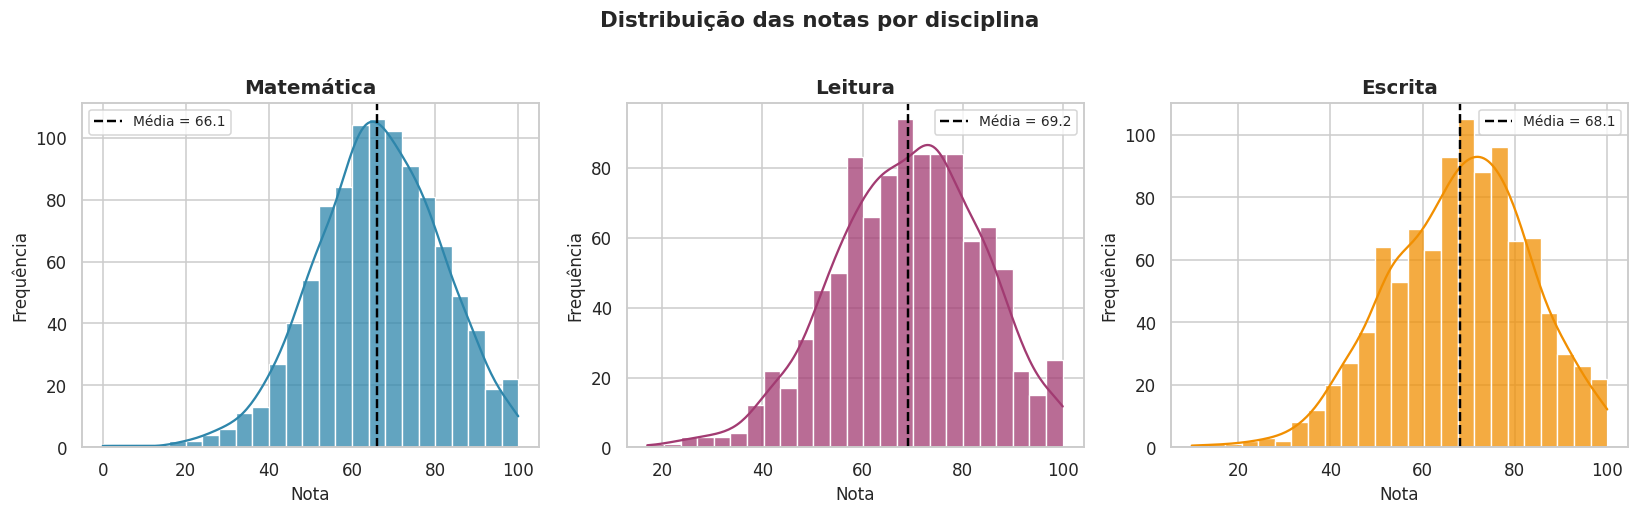

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, col, cor in zip(axes, NOTAS, PALETA):
    sns.histplot(df[col], bins=25, kde=True, color=cor, ax=ax,
                 edgecolor="white", alpha=0.75)
    ax.axvline(df[col].mean(), color="black", linestyle="--", linewidth=1.6,
               label=f"Média = {df[col].mean():.1f}")
    ax.set_title(NOMES_DISCIPLINA[col])
    ax.set_xlabel("Nota")
    ax.set_ylabel("Frequência")
    ax.legend(fontsize=9)

fig.suptitle("Distribuição das notas por disciplina", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

> **Lê-se:** as três distribuições são aproximadamente normais, centradas perto de 66–69,
> com assimetria negativa — uma minoria de alunos com notas muito baixas puxa a cauda
> esquerda. Matemática é a mais espalhada (maior desvio-padrão).

### Gráfico 2 — Meninos e meninas vão bem nas mesmas coisas?

Boxplots lado a lado. O boxplot mostra mediana (linha central), quartis (caixa) e
outliers (pontos) — muito mais informativo que uma barra de média.

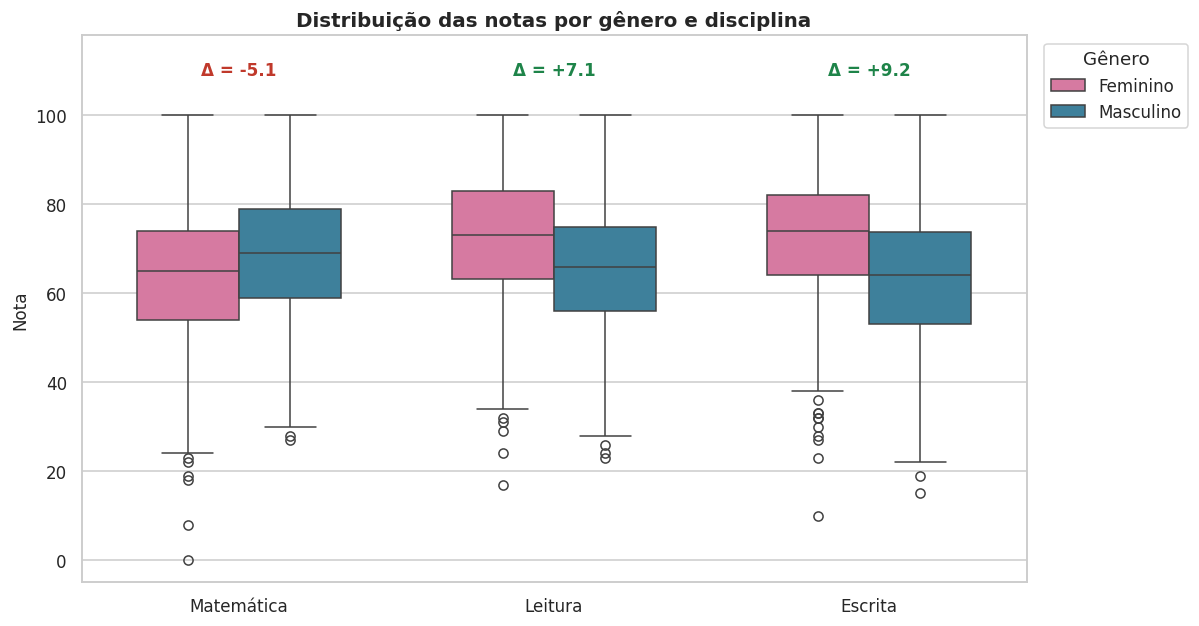

In [20]:
# Formato "longo": uma linha por (aluno, disciplina) — exigido pelo seaborn
dados_longos = df.melt(id_vars="genero", value_vars=NOTAS,
                       var_name="disciplina", value_name="nota")

# Traduzimos os VALORES antes de plotar (em vez de sobrescrever os rótulos
# da legenda depois) — assim é impossível trocar as categorias por engano
dados_longos["disciplina"] = dados_longos["disciplina"].map(NOMES_DISCIPLINA)
dados_longos["genero"] = dados_longos["genero"].astype(str).map(ROTULOS)

ordem_disc = list(NOMES_DISCIPLINA.values())

plt.figure(figsize=(11, 5.8))
ax = sns.boxplot(data=dados_longos, x="disciplina", y="nota", hue="genero",
                 order=ordem_disc, hue_order=["Feminino", "Masculino"],
                 palette={"Feminino": "#E56B9F", "Masculino": "#2E86AB"},
                 width=0.65)
ax.set_title("Distribuição das notas por gênero e disciplina")
ax.set_xlabel("")
ax.set_ylabel("Nota")
ax.legend(title="Gênero", bbox_to_anchor=(1.01, 1), loc="upper left")

# Anota a diferença de médias (feminino - masculino) em cada disciplina
medias = df.groupby("genero", observed=True)[NOTAS].mean()
for i, col in enumerate(NOTAS):
    dif = medias.loc["female", col] - medias.loc["male", col]
    ax.text(i, 109, f"Δ = {dif:+.1f}", ha="center", fontsize=11,
            fontweight="bold", color="#C0392B" if dif < 0 else "#1E8449")
ax.set_ylim(-5, 118)
plt.tight_layout()
plt.show()

> **Lê-se:** o padrão se **inverte** conforme a disciplina. Meninos levam vantagem em
> matemática (+5,1), meninas em leitura (+7,1) e escrita (+9,2). Não existe um gênero
> "melhor aluno" — existem áreas com desempenho diferente.

### Gráfico 3 — O curso preparatório funciona?

Barras agrupadas comparando quem completou e quem não fez o curso, com o valor anotado
em cada barra para leitura direta.

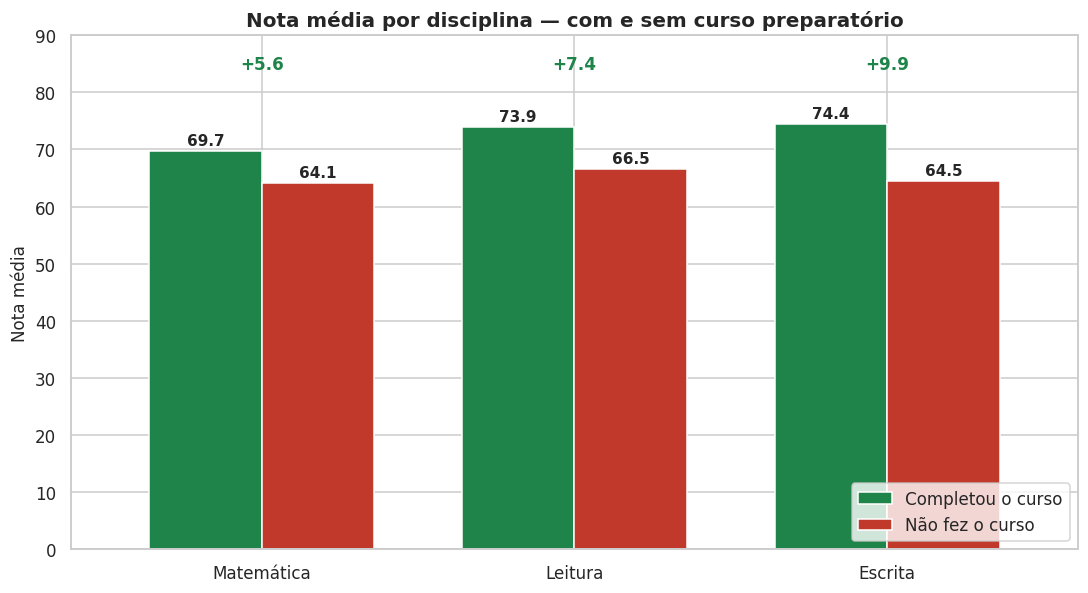

In [21]:
comp = (df.groupby("curso_preparatorio", observed=True)[NOTAS]
          .mean().T.round(2))

# Ordem e nomes definidos explicitamente -> legenda sempre correta
comp = comp[["completed", "none"]]
comp.index = [NOMES_DISCIPLINA[i] for i in comp.index]
comp.columns = ["Completou o curso", "Não fez o curso"]

ax = comp.plot(kind="bar", figsize=(10, 5.5), width=0.72,
               color=["#1E8449", "#C0392B"], edgecolor="white")
ax.set_title("Nota média por disciplina — com e sem curso preparatório")
ax.set_xlabel("")
ax.set_ylabel("Nota média")
ax.tick_params(axis="x", rotation=0)
ax.legend(title=None, loc="lower right")
ax.set_ylim(0, 90)

for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f", fontsize=10, fontweight="bold", padding=2)

# Ganho de cada disciplina
for i, disc in enumerate(comp.index):
    ganho = comp.loc[disc, "Completou o curso"] - comp.loc[disc, "Não fez o curso"]
    ax.text(i, 84, f"+{ganho:.1f}", ha="center", fontsize=11,
            fontweight="bold", color="#1E8449")

plt.tight_layout()
plt.show()

> **Lê-se:** o curso está associado a ganho em **todas** as disciplinas, e o ganho é maior
> justamente onde a escrita é exigida (+9,9 pontos) — coerente com o tipo de treino
> oferecido por cursos preparatórios.

### Gráfico 4 — A escolaridade dos pais influencia?

Barras horizontais ordenadas. O formato horizontal foi escolhido porque os rótulos das
categorias são longos e ficariam ilegíveis na vertical.

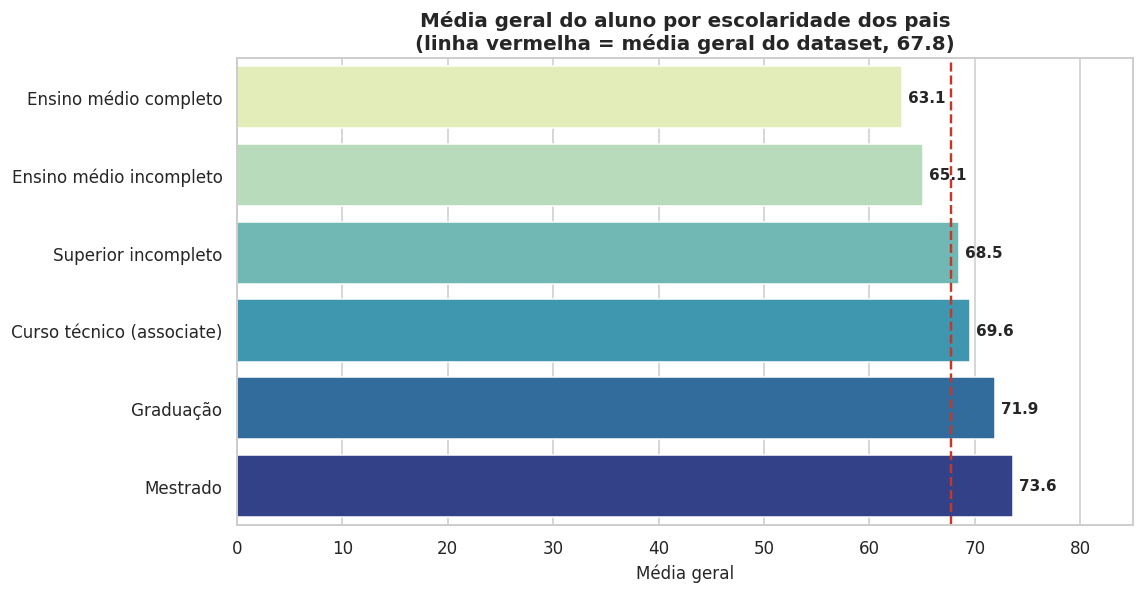

In [22]:
ordem = ["high school", "some high school", "some college",
         "associate's degree", "bachelor's degree", "master's degree"]
medias_pais = (df.groupby("escolaridade_pais", observed=True)["media_geral"]
                 .mean().reindex(ordem).round(2))

rotulos_pt = [ROTULOS[i] for i in medias_pais.index]
media_global = df["media_geral"].mean()

plt.figure(figsize=(10.5, 5.5))
ax = sns.barplot(x=medias_pais.values, y=rotulos_pt, hue=rotulos_pt,
                 palette=sns.color_palette("YlGnBu", len(medias_pais)),
                 legend=False)
ax.set_title("Média geral do aluno por escolaridade dos pais\n"
             f"(linha vermelha = média geral do dataset, {media_global:.1f})")
ax.set_xlabel("Média geral")
ax.set_ylabel("")
ax.set_xlim(0, 85)

for cont in ax.containers:                    # uma barra por container
    ax.bar_label(cont, fmt="%.1f", fontsize=10, fontweight="bold", padding=4)

ax.axvline(media_global, color="#C0392B", linestyle="--", linewidth=1.6)

plt.tight_layout()
plt.show()

> **Lê-se:** existe um **gradiente perfeitamente monotônico** — a cada degrau de
> escolaridade dos pais, a média do filho sobe. Do menor ao maior nível são **10,5 pontos**
> de diferença. É o efeito individual mais forte de todo o dataset (d = 0,78).

### Gráfico 5 — O nível socioeconômico separa os alunos?

Boxplot por tipo de almoço. Usamos o almoço subsidiado como **proxy de baixa renda**,
já que é o critério oficial de elegibilidade no sistema escolar americano.

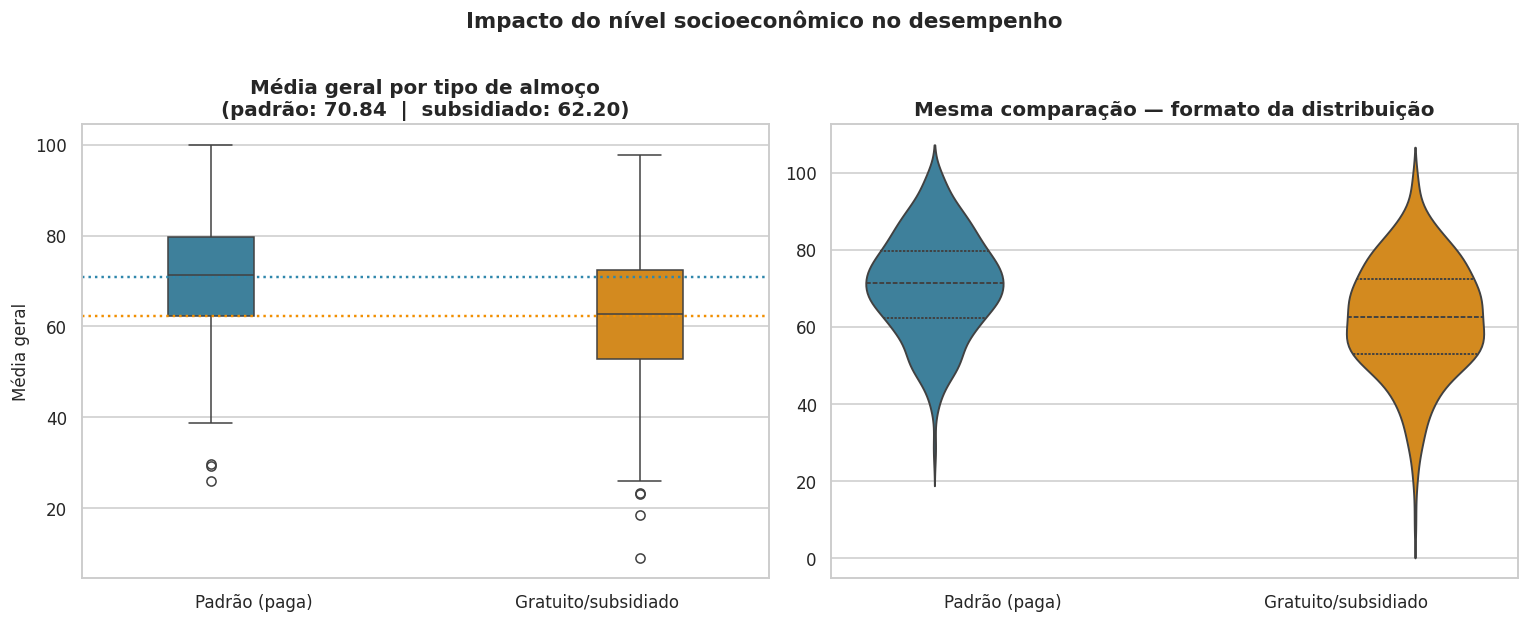

In [23]:
# ATENÇÃO: a ordem das categorias precisa ser declarada explicitamente com
# 'order='. Sem isso o seaborn ordena alfabeticamente (free/reduced vem
# antes de standard) e os rótulos manuais ficariam invertidos.
# Criamos uma coluna já traduzida e com ordem fixa. Isso garante que
# boxplot e violinplot usem exatamente a mesma cor para a mesma categoria.
ROT = ["Padrão (paga)", "Gratuito/subsidiado"]
CORES = {"Padrão (paga)": "#2E86AB", "Gratuito/subsidiado": "#F18F01"}

df_plot = df.copy()
df_plot["almoco"] = pd.Categorical(
    df_plot["tipo_almoco"].astype(str).map(ROTULOS), categories=ROT, ordered=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.boxplot(data=df_plot, x="almoco", y="media_geral", order=ROT,
            hue="almoco", hue_order=ROT, palette=CORES,
            legend=False, width=0.5, ax=axes[0])
sns.violinplot(data=df_plot, x="almoco", y="media_geral", order=ROT,
               hue="almoco", hue_order=ROT, palette=CORES,
               legend=False, inner="quartile", ax=axes[1])

medias = df_plot.groupby("almoco", observed=True)["media_geral"].mean()

axes[0].set_title(f"Média geral por tipo de almoço\n"
                  f"(padrão: {medias[ROT[0]]:.2f}  |  subsidiado: {medias[ROT[1]]:.2f})")
axes[0].set_ylabel("Média geral")
axes[1].set_title("Mesma comparação — formato da distribuição")
axes[1].set_ylabel("")

for ax in axes:
    ax.set_xlabel("")

# Linhas horizontais marcando a média de cada grupo
for rot in ROT:
    axes[0].axhline(medias[rot], color=CORES[rot], linestyle=":", linewidth=1.6)

fig.suptitle("Impacto do nível socioeconômico no desempenho",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

> **Lê-se:** a caixa inteira do grupo subsidiado está deslocada para baixo, e o violino
> mostra que a cauda de notas muito baixas é bem mais densa nesse grupo. Diferença de
> **8,6 pontos** na média (d = 0,63).

### Gráfico 6 — As disciplinas andam juntas?

Heatmap da matriz de correlação. Cores quentes = correlação alta. É a forma mais rápida
de ler uma matriz de números.

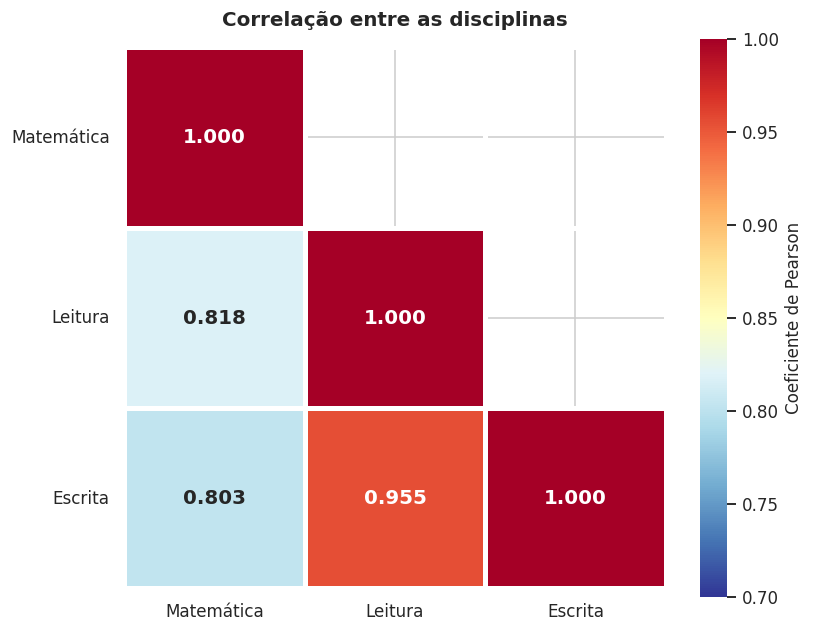

In [24]:
plt.figure(figsize=(7.5, 6))
mascara = np.triu(np.ones_like(df[NOTAS].corr(), dtype=bool), k=1)
ax = sns.heatmap(df[NOTAS].corr(), annot=True, fmt=".3f", cmap="RdYlBu_r",
                 vmin=0.7, vmax=1, square=True, linewidths=2, mask=mascara,
                 cbar_kws={"label": "Coeficiente de Pearson"},
                 annot_kws={"size": 13, "weight": "bold"})
ax.set_title("Correlação entre as disciplinas", pad=14)
rotulos = ["Matemática", "Leitura", "Escrita"]
ax.set_xticklabels(rotulos, rotation=0)
ax.set_yticklabels(rotulos, rotation=0)
plt.tight_layout()
plt.show()

> **Lê-se:** leitura e escrita são **quase a mesma competência** (r = 0,955). Matemática
> se correlaciona forte com as duas (0,80–0,82), mas é a mais independente — o que faz
> sentido: ela depende de habilidades específicas além da leitura.

### Gráfico 7 — Visualizando a correlação leitura × escrita

Gráfico de dispersão com reta de regressão. A cor distingue quem fez o curso preparatório,
revelando **duas informações no mesmo gráfico**.

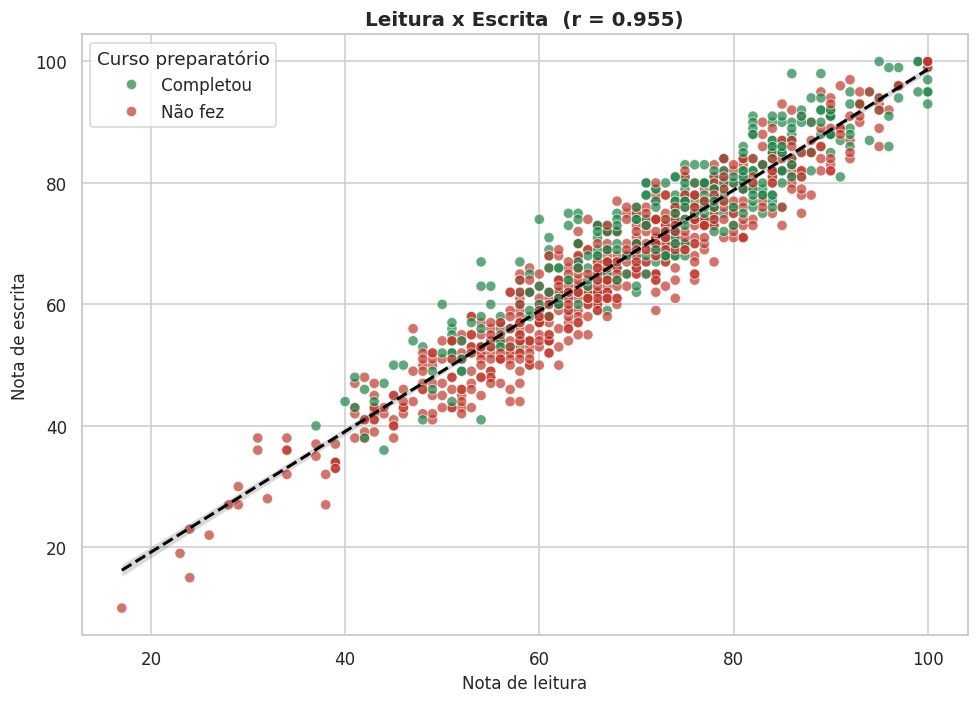

In [25]:
# Traduz os valores antes de plotar para a legenda sair correta
df_plot = df.copy()
df_plot["curso"] = (df_plot["curso_preparatorio"].astype(str)
                    .map({"completed": "Completou", "none": "Não fez"}))

plt.figure(figsize=(9, 6.5))
ax = sns.scatterplot(data=df_plot, x="nota_leitura", y="nota_escrita",
                     hue="curso", hue_order=["Completou", "Não fez"],
                     palette={"Completou": "#1E8449", "Não fez": "#C0392B"},
                     alpha=0.7, s=45)
sns.regplot(data=df, x="nota_leitura", y="nota_escrita", scatter=False,
            color="black", line_kws={"linewidth": 2, "linestyle": "--"}, ax=ax)

r = df["nota_leitura"].corr(df["nota_escrita"])
ax.set_title(f"Leitura x Escrita  (r = {r:.3f})")
ax.set_xlabel("Nota de leitura")
ax.set_ylabel("Nota de escrita")
ax.legend(title="Curso preparatório", loc="upper left")
plt.tight_layout()
plt.show()

> **Lê-se:** os pontos formam uma faixa estreita em torno da reta — relação praticamente
> linear. Os pontos verdes (com curso) concentram-se no canto superior direito, mostrando
> visualmente o efeito do preparatório.

### Gráfico 8 — Onde está a reprovação?

Painel de barras com a taxa de alunos abaixo de 60 por grupo. Média alta pode esconder
muita gente reprovando; este gráfico mostra o tamanho real do problema.

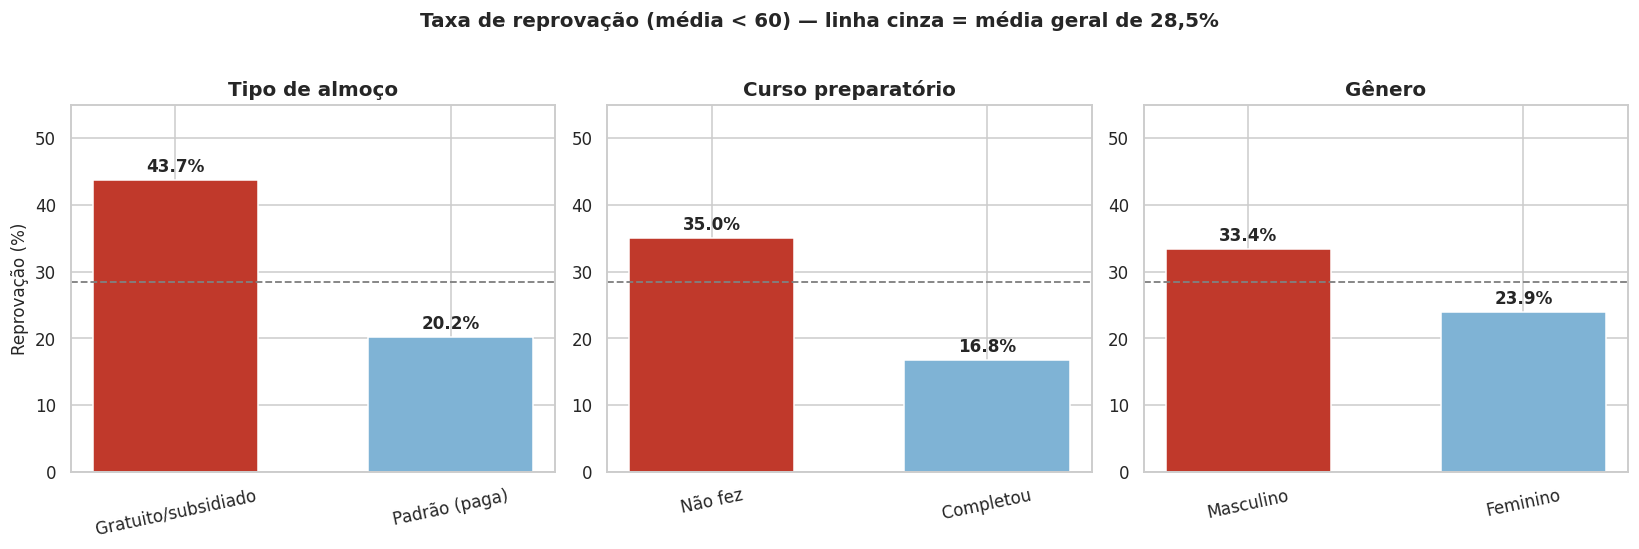

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
config = [("tipo_almoco", "Tipo de almoço"),
          ("curso_preparatorio", "Curso preparatório"),
          ("genero", "Gênero")]

for ax, (col, titulo) in zip(axes, config):
    taxa = (df.groupby(col, observed=True)["situacao"]
              .apply(lambda s: (s == "Reprovado").mean() * 100)
              .sort_values(ascending=False))
    rotulos = [ROTULOS.get(str(i), str(i)).replace(" o curso", "")
               for i in taxa.index]
    cores = ["#C0392B" if v == taxa.max() else "#7FB3D5" for v in taxa.values]
    b = ax.bar(rotulos, taxa.values, color=cores,
               edgecolor="white", width=0.6)
    ax.bar_label(b, fmt="%.1f%%", fontsize=11, fontweight="bold", padding=3)
    ax.axhline(28.5, color="gray", linestyle="--", linewidth=1.2)
    ax.set_title(titulo)
    ax.set_ylabel("Reprovação (%)" if col == "tipo_almoco" else "")
    ax.set_ylim(0, 55)
    ax.tick_params(axis="x", rotation=12)

fig.suptitle("Taxa de reprovação (média < 60) — linha cinza = média geral de 28,5%",
             fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

> **Lê-se:** a reprovação entre alunos com almoço subsidiado (**43,7%**) é mais que o
> **dobro** da observada no grupo com almoço padrão (20,2%). O curso preparatório
> reduz a reprovação de 35,0% para 16,8% — praticamente pela metade.

### Gráfico 9 — O efeito combinado dos dois fatores mais fortes

Heatmap cruzando nível socioeconômico e curso preparatório. Mostra o que acontece quando
os fatores se somam — a informação mais importante do relatório.

Gap entre o melhor e o pior cenário: 16.56 pontos


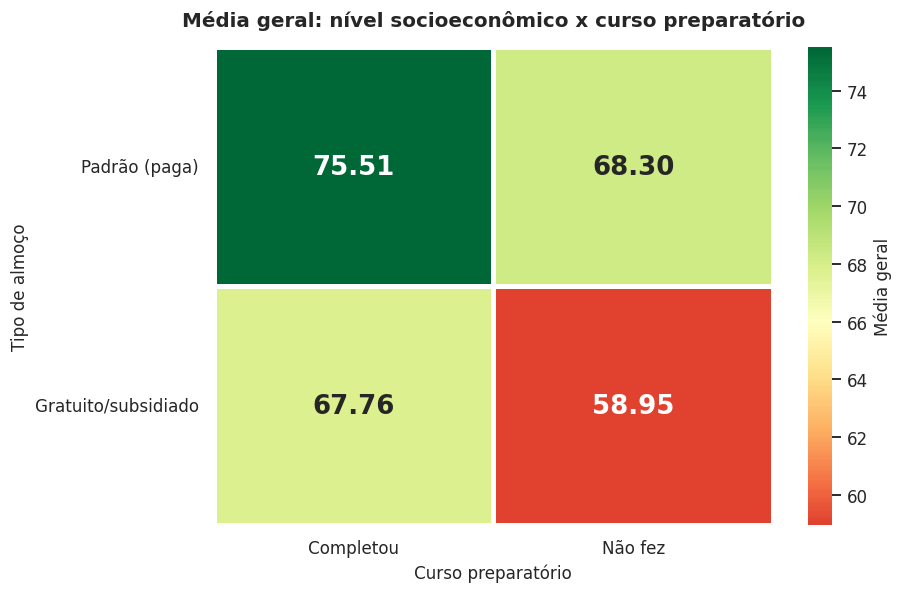

In [27]:
tabela = (df.pivot_table(index="tipo_almoco", columns="curso_preparatorio",
                         values="media_geral", aggfunc="mean", observed=True)
            .reindex(index=["standard", "free/reduced"],      # ordem explícita
                     columns=["completed", "none"]))

plt.figure(figsize=(8.5, 5.5))
ax = sns.heatmap(tabela, annot=True, fmt=".2f", cmap="RdYlGn", center=66,
                 linewidths=3, square=False, annot_kws={"size": 17, "weight": "bold"},
                 cbar_kws={"label": "Média geral"})
ax.set_title("Média geral: nível socioeconômico x curso preparatório", pad=14)
ax.set_xlabel("Curso preparatório")
ax.set_ylabel("Tipo de almoço")
ax.set_xticklabels(["Completou", "Não fez"], rotation=0)
ax.set_yticklabels(["Padrão (paga)", "Gratuito/subsidiado"], rotation=0)
plt.tight_layout()
plt.show()

print(f"Gap entre o melhor e o pior cenário: "
      f"{tabela.max().max() - tabela.min().min():.2f} pontos")

> **Lê-se:** os efeitos **se acumulam**. Um aluno com almoço padrão que fez o curso tem
> média **75,51**; um aluno com almoço subsidiado que não fez o curso tem **58,95** —
> **16,56 pontos de diferença**, ou aproximadamente 1,1 desvio-padrão.
>
> O achado mais importante está na **diagonal**: o aluno de baixa renda **que fez o curso**
> (67,76) praticamente empata com o aluno de renda mais alta **que não fez** (68,30) —
> apenas 0,54 ponto separa os dois. Ou seja, **o curso preparatório compensa quase
> integralmente a desvantagem socioeconômica.**

---

# 4. 🔍 Identificação de insights

Consolidamos abaixo os achados que se sustentam nos números — cada um com sua evidência
estatística.

In [28]:
print("=" * 70)
print("PAINEL DE INSIGHTS".center(70))
print("=" * 70)

media_g = df["media_geral"].mean()

# 1
alm = df.groupby("tipo_almoco", observed=True)["media_geral"].mean()
print(f"\n[1] NIVEL SOCIOECONOMICO E O DIVISOR MAIS FORTE")
print(f"    Almoco padrao ....... {alm['standard']:.2f}")
print(f"    Almoco subsidiado ... {alm['free/reduced']:.2f}")
print(f"    Diferenca ........... {alm['standard'] - alm['free/reduced']:.2f} pontos (d = 0.63)")

# 2
cur = df.groupby("curso_preparatorio", observed=True)["media_geral"].mean()
rep = df.groupby("curso_preparatorio", observed=True)["situacao"].apply(
    lambda s: (s == "Reprovado").mean() * 100)
print(f"\n[2] O CURSO PREPARATORIO E A ALAVANCA MAIS ACIONAVEL")
print(f"    Media com curso ..... {cur['completed']:.2f}   (reprovacao {rep['completed']:.1f}%)")
print(f"    Media sem curso ..... {cur['none']:.2f}   (reprovacao {rep['none']:.1f}%)")
print(f"    Ganho ............... {cur['completed'] - cur['none']:.2f} pontos")
print(f"    Alcance atual ....... apenas {(df['curso_preparatorio']=='completed').mean()*100:.1f}% dos alunos")

# 3
gen = df.groupby("genero", observed=True)[NOTAS].mean()
print(f"\n[3] O PADRAO DE GENERO SE INVERTE POR DISCIPLINA")
for col in NOTAS:
    d = gen.loc['female', col] - gen.loc['male', col]
    lider = "meninas" if d > 0 else "meninos"
    print(f"    {col.replace('nota_',''):12s}: {abs(d):5.2f} pontos a favor de {lider}")

# 4
ordem_e = ["high school", "some high school", "some college",
           "associate's degree", "bachelor's degree", "master's degree"]
esc = df.groupby("escolaridade_pais", observed=True)["media_geral"].mean().reindex(ordem_e)
print(f"\n[4] ESCOLARIDADE DOS PAIS: GRADIENTE MONOTONICO")
print(f"    Ensino medio ........ {esc.iloc[0]:.2f}")
print(f"    Mestrado ............ {esc.iloc[-1]:.2f}")
print(f"    Amplitude ........... {esc.iloc[-1] - esc.iloc[0]:.2f} pontos (d = 0.78, o maior efeito)")

# 5
corr_le = df["nota_leitura"].corr(df["nota_escrita"])
corr_ml = df["nota_matematica"].corr(df["nota_leitura"])
print(f"\n[5] LEITURA E ESCRITA SAO PRATICAMENTE A MESMA COMPETENCIA")
print(f"    r(leitura, escrita) ..... {corr_le:.3f}")
print(f"    r(matematica, leitura) .. {corr_ml:.3f}")
print(f"    Matematica e a disciplina mais 'independente' e a de menor media ({df['nota_matematica'].mean():.2f})")

# 6
piv = df.pivot_table(index="tipo_almoco", columns="curso_preparatorio",
                     values="media_geral", aggfunc="mean", observed=True)
print(f"\n[6] OS EFEITOS SE ACUMULAM")
print(f"    Melhor cenario (padrao + curso) ....... {piv.loc['standard','completed']:.2f}")
print(f"    Pior cenario (subsidiado + sem curso) . {piv.loc['free/reduced','none']:.2f}")
print(f"    Gap ................................... {piv.max().max()-piv.min().min():.2f} pontos")
print(f"    Baixa renda COM curso ({piv.loc['free/reduced','completed']:.2f}) quase alcanca")
print(f"    alta renda SEM curso ({piv.loc['standard','none']:.2f}) -> o curso compensa a desvantagem")
print("\n" + "=" * 70)

                          PAINEL DE INSIGHTS                          

[1] NIVEL SOCIOECONOMICO E O DIVISOR MAIS FORTE
    Almoco padrao ....... 70.84
    Almoco subsidiado ... 62.20
    Diferenca ........... 8.64 pontos (d = 0.63)

[2] O CURSO PREPARATORIO E A ALAVANCA MAIS ACIONAVEL
    Media com curso ..... 72.67   (reprovacao 16.8%)
    Media sem curso ..... 65.04   (reprovacao 35.0%)
    Ganho ............... 7.63 pontos
    Alcance atual ....... apenas 35.8% dos alunos

[3] O PADRAO DE GENERO SE INVERTE POR DISCIPLINA
    matematica  :  5.10 pontos a favor de meninos
    leitura     :  7.14 pontos a favor de meninas
    escrita     :  9.16 pontos a favor de meninas

[4] ESCOLARIDADE DOS PAIS: GRADIENTE MONOTONICO
    Ensino medio ........ 63.10
    Mestrado ............ 73.60
    Amplitude ........... 10.50 pontos (d = 0.78, o maior efeito)

[5] LEITURA E ESCRITA SAO PRATICAMENTE A MESMA COMPETENCIA
    r(leitura, escrita) ..... 0.955
    r(matematica, leitura) .. 0.818
    Mate

## 🔍 Os 6 insights em detalhe

### Insight 1 — O nível socioeconômico é o divisor mais visível
Alunos com almoço gratuito/subsidiado têm média **62,20** contra **70,84** dos demais:
**8,64 pontos** de diferença (p < 0,001; d = 0,63, efeito médio-alto). O impacto é ainda
mais dramático na reprovação: **43,7% contra 20,2%** — mais que o dobro. Os cinco piores
desempenhos individuais do dataset pertencem, todos, a esse grupo.

### Insight 2 — O curso preparatório é a alavanca mais acionável
Quem completou o curso tem média **72,67** contra **65,04** (+7,63 pontos, d = 0,55) e
reprova **menos da metade**: 16,8% contra 35,0%. É o único fator da base que uma escola
consegue mudar diretamente — e hoje ele alcança apenas **35,8% dos alunos**.

### Insight 3 — O padrão de gênero se inverte conforme a disciplina
Não existe um gênero com desempenho superior; existem **áreas** distintas. Meninos lideram
em matemática (**+5,1**), meninas em leitura (**+7,1**) e escrita (**+9,2**). A vantagem
feminina em escrita (d = 0,63) é maior em magnitude que a vantagem masculina em
matemática (d = 0,34).

### Insight 4 — A escolaridade dos pais produz um gradiente perfeito
As médias sobem de forma **monotônica** em todos os seis níveis: 63,10 (ensino médio) →
65,11 → 68,48 → 69,57 → 71,92 → **73,60** (mestrado). São **10,5 pontos** entre os extremos,
o **maior tamanho de efeito da base (d = 0,78)**. Capital cultural familiar aparece nos
dados com uma regularidade quase de manual.

### Insight 5 — Leitura e escrita são quase a mesma competência
r = **0,955** — próximo do máximo teórico. Isso significa que quem melhora em leitura
melhora em escrita quase na mesma proporção; reforço separado nas duas seria redundante.
Matemática, com r ≈ 0,80, é a mais independente **e** a de menor média (66,09) e maior
dispersão (dp = 15,16) — a disciplina mais crítica e mais desigual.

### Insight 6 — Os efeitos se acumulam (e o curso quase anula a desvantagem)
Combinando os dois fatores mais fortes, o gap chega a **16,56 pontos** (75,51 vs 58,95).
Mas o dado mais esperançoso está na diagonal: alunos de baixa renda que fizeram o curso
alcançam **67,76**, praticamente empatando com alunos de renda mais alta que não fizeram
o curso (**68,30**). **O curso preparatório compensa quase integralmente a desvantagem
socioeconômica.**

---

# 5. 📋 Conclusões e recomendações

## 5.1 Conclusão geral

O desempenho dos 1.000 estudantes analisados **não é distribuído aleatoriamente**: ele é
explicado, de forma estatisticamente robusta, por um pequeno conjunto de fatores de contexto.

Os fatores se organizam em duas naturezas distintas:

| Natureza | Fatores | Efeito | A escola pode mudar? |
|---|---|---|---|
| **Estrutural** | Escolaridade dos pais, nível socioeconômico | d = 0,78 / d = 0,63 | ❌ Não diretamente |
| **Institucional** | Curso preparatório | d = 0,55 | ✅ **Sim** |

Essa separação é a conclusão central do trabalho: **os fatores mais fortes são os que a
escola não controla, mas o fator controlável tem magnitude suficiente para compensá-los.**
Alunos de baixa renda que completaram o curso preparatório praticamente empatam com alunos
de renda mais alta que não o fizeram (67,76 vs 68,30).

## 5.2 Recomendações

**1. Universalizar o curso preparatório, priorizando quem mais precisa** — *prioridade máxima*
Hoje 64,2% dos alunos não fazem o curso. Entre alunos com almoço subsidiado, 63,1% estão
de fora. Expandir a oferta para esse grupo é a ação com maior retorno esperado, já que ele
combina o maior déficit com o efeito comprovado de +7,63 pontos.

**2. Investigar as barreiras de acesso ao curso**
Antes de expandir, é preciso entender *por que* dois terços não participam: custo, horário,
transporte ou desconhecimento? A base não responde isso — exige pesquisa com os alunos.

**3. Criar um programa específico de reforço em matemática**
Matemática tem a menor média (66,09), a maior dispersão (dp = 15,16) e a maior reprovação
(32,3%). Além disso, é a disciplina **menos correlacionada** com as demais — ou seja, quem
vai mal nela não é necessariamente um aluno fraco em geral, e precisa de intervenção dirigida.

**4. Tratar leitura e escrita como um único eixo de reforço**
Com r = 0,955, programas separados desperdiçam recurso. Uma intervenção integrada de
letramento atinge as duas competências simultaneamente.

**5. Implantar um sistema de alerta precoce**
Cruzando apenas dois campos já disponíveis na matrícula (tipo de almoço e participação no
curso), a escola identifica o grupo com 43,7% de reprovação **antes** da primeira avaliação
— tempo suficiente para agir preventivamente.

**6. Envolver as famílias de menor escolaridade**
O gradiente monotônico mostra que o capital cultural familiar pesa muito. Programas de
letramento familiar e orientação aos responsáveis atacam a raiz do maior efeito da base.

## 5.3 Limitações do estudo

Ser honesto sobre os limites é parte da análise:

- **Correlação não é causalidade.** Não sabemos se o curso *causa* a nota melhor ou se
  alunos já mais dedicados é que se inscrevem no curso (viés de autosseleção). Só um
  experimento controlado responderia isso.
- **Variáveis ausentes.** Não há dados sobre frequência, horas de estudo, qualidade da
  escola, tamanho da turma ou renda familiar direta.
- **`race/ethnicity` é anonimizada.** Os rótulos "group A–E" não têm significado divulgado,
  o que impede qualquer interpretação sociológica responsável — por isso essa variável foi
  usada apenas descritivamente neste relatório.
- **Amostra pequena em alguns estratos.** O `group A` tem 89 alunos e o nível "mestrado"
  apenas 59 — médias menos estáveis.
- **Corte de 60 pontos é convencional.** A classificação Aprovado/Reprovado segue o padrão
  da escala americana, mas é uma escolha do analista, não um dado do arquivo.
- **Dataset sintético.** Esta base do Kaggle é fictícia, criada para fins educacionais.
  Os padrões encontrados são internamente consistentes, mas não representam uma população real.

## 5.4 Próximos passos

- Treinar um modelo preditivo (regressão logística) para estimar risco de reprovação
- Aplicar ANOVA de dois fatores para testar formalmente a interação almoço × curso
- Coletar dados longitudinais para viabilizar inferência causal

In [29]:
print("=" * 62)
print("ANALISE CONCLUIDA".center(62))
print("=" * 62)
print(f"Registros analisados ....... {len(df)}")
print(f"Variaveis finais ........... {df.shape[1]}")
print(f"Graficos gerados ........... 9")
print(f"Testes estatisticos ........ 4 (todos com p < 0.001)")
print(f"Insights identificados ..... 6")
print(f"Recomendacoes .............. 6")
print("=" * 62)

                      ANALISE CONCLUIDA                       
Registros analisados ....... 1000
Variaveis finais ........... 11
Graficos gerados ........... 9
Testes estatisticos ........ 4 (todos com p < 0.001)
Insights identificados ..... 6
Recomendacoes .............. 6
